In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler 
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix , classification_report
import seaborn as sns

# Fonctions d'activation

In [2]:
#ReLU
def relu(X) : 
   # Validate input
    assert isinstance(X , np.ndarray), "Input to ReLU must be a NumPy ndarray"
    assert X.size > 0, "Input array cannot be empty"
    result = np.maximum(0, X)
    # Validate output
    assert isinstance(result , np.ndarray), "Output must be a NumPy ndarray"
    assert result.shape == X.shape , "Output shape must match input shape"
    assert np.all(result >= 0), "ReLU output must be non -negative"
    return result
    
def relu_derivative(X):
     #Validate input
    assert isinstance(X,np.ndarray), "Input to ReLU derivative must be a NumPY ndarray"
    result = np.where(X > 0, 1, 0)
    # Validate output
    assert ((result == 0) | (result == 1)).all(), " ReLU derivative must be 0 or 1"
    return result

In [3]:
def sigmoid(X) : 
    # Validate input
    assert isinstance(X , np.ndarray), "Input must be a NumPy ndarray"
    assert X.size > 0, "Input array cannot be empty"
    result = 1/(1 + np.exp(-X))
    # Validate output
    assert isinstance(result , np.ndarray), "Output must be a NumPy ndarray"
    assert result.shape == X.shape , "Output shape must match input shape"
    assert np.all((result >= 0)&(result <=1)), "Sigmoid output must be in [0,1]"
    return result

def sigmoid_derivative(X) : 
    assert isinstance(X, np.ndarray), "L'entrée doit être un tableau numpy (np.ndarray)"
    assert np.all((sigmoid(X)> 0) & (sigmoid(X) < 1)), "Les valeurs de sigmoid doivent être strictement entre 0 et 1"

    result = sigmoid(X) * (1 - sigmoid(X))
    assert np.all((result > 0) & (result < 0.25)), "Les valeurs de la dérivée doivent être entre 0 et 0.25"
    
    return result

# La class NN

In [66]:
class NeuralNetwork : 
    def __init__(self,layer_sizes,learning_rate = 0.01,lambda_ = 0.5,optimizer="sgd") : 
        assert isinstance(layer_sizes , list) and len(layer_sizes) >= 2 , "Layer_sizes must be a list with at least 2 elements"
        assert all(isinstance(size , int) and size > 0 for size in layer_sizes) , "All layer must be posiyive integrs"
        assert isinstance(learning_rate , (int,float)) and learning_rate > 0 , " learning rate must be a positive number"
        self.layer_sizes = layer_sizes
        self.learning_rate = learning_rate
        self.lambda_ = lambda_
        self.weights = [] 
        self.biases = [] 
        # Inisialisation des poids et biais 
        np.random.seed(42)
        for i in range(len(layer_sizes) - 1) : 
            w , b = np.random.randn(layer_sizes[i],layer_sizes[i+1]) , np.zeros((1 , layer_sizes[i+1]))
            assert w.shape == ( layer_sizes [ i], layer_sizes [ i +1]) ," Weight matrix {i +1} has incorrect shape "
            assert b.shape == (1 , layer_sizes [ i +1]) , " Bias vector {i +1} has incorrect shape "                                                       
            self.weights.append (w)
            self.biases.append (b)
            
        self.optimizer = optimizer.lower()
        if self.optimizer == "adam":
            self.beta1 = 0.9
            self.beta2 = 0.99
            self.epsilon = 1e-8
            self.m_weights = [np.zeros_like(w) for w in self.weights]
            self.v_weights = [np.zeros_like(w) for w in self.weights]
            self.m_biases = [np.zeros_like(b) for b in self.biases]
            self.v_biases = [np.zeros_like(b) for b in self.biases]
                                   
    def forward(self,X) : 
        assert isinstance(X,np.ndarray),"Input X must be a numpy array"
        assert X.shape[1] == self.layer_sizes[0] , f"Input dimension ({X.shape [1]}) must match input layer size ({self.layer_sizes [0]})"
        self.activations = [X]
        self.z_values = []
        for i in range(len(self.weights)-1) : 
            z = np.dot(self.activations[-1],self.weights[i]) + self.biases[i]
            assert z. shape == ( X. shape [0] , self . layer_sizes [i +1]) ,f"Z^{[ i +1]} has incorrect shape "
            self.z_values.append(z)
            self.activations.append(relu(z))
        
        z = np.dot(self.activations [-1],self.weights[-1]) + self.biases[-1]
        assert z.shape == (X.shape[0], self.layer_sizes[-1]), "Output Z has incorrect shape" 
        self.z_values.append(z)
        output = sigmoid(z) 
        assert output.shape == (X.shape[0], self.layer_sizes[-1]), "Output A has incorrect shape" 
        self.activations.append(output)
        return self.activations[-1] 
    def compute_loss(self,y_true,y_pred) : 
        assert isinstance(y_true, np.ndarray) and isinstance(y_pred , np.ndarray) , "Inputs to loss must be numpy arrays"
        assert y_true.shape == y_pred.shape , "y_true and y_pred must have the same shape" 
        assert np.all((y_true == 0) | (y_true ==1)),"y_true must contain only 0s and 1s"
        m = y_true.shape[0]
        epsilon = 1e-15
        y_pred_clipped = np.clip(y_pred,epsilon,1- epsilon)

        loss = -1/m * np.sum(y_true * np.log(y_pred_clipped) + (1 - y_true) * np.log(1 - y_pred_clipped))
        assert not np .isnan(loss) , " Loss computation resulted in NaN "
        return loss
    def compute_accuracy(self,y_true,y_pred) : 
        assert isinstance(y_true , np.ndarray) and isinstance(y_pred,np.ndarray) , "Inputs to accuracy must be numpy arrays"
        assert y_true.shape == y_pred.shape,"y_true and y_pred must have the same shape"
        y_pred_labels = (y_pred >= 0.5).astype(int)
        correct_predictions = (y_pred_labels == y_true).astype(int)
        accuracy = np.mean(correct_predictions)
        assert 0 <= accuracy <= 1 , " Accuracy must be between 0 and 1"
        return accuracy 
        
    def backward(self,X,y,outputs) : 
        assert isinstance (X , np . ndarray ) and isinstance (y , np.ndarray ) and isinstance ( outputs , np . ndarray ) , " Inputs to backward must be numpy arrays "
        assert X.shape[1] == self.layer_sizes[0],f" Input dimension ({X. shape [1]}) must match input layer size ({self . layer_sizes [0]}) "
        assert y.shape == outputs.shape,"y and outputs must have the same shape"
        m = X.shape[0]
        self.d_weights = [np.zeros_like(w) for w in self.weights]
        self.d_biases = [np.zeros_like(b) for b in self.biases]

        dZ = outputs - y 
        assert dZ.shape == outputs.shape ,"dZ for output layer has incorrect shape"
        self.d_weights[-1] = (self.activations[-2].T @ dZ)/m
        self.d_biases[-1] = np.sum(dZ , axis = 0 , keepdims =True)/m

        for i in range(len(self.weights) -2,-1,-1) : 
            dA = dZ @ self.weights[i+1].T
            dZ = dA * relu_derivative(self.z_values[i])

            self.d_weights[i] = (self.activations[i].T @ dZ)/m
            self.d_biases[i] = np.sum(dZ, axis=0, keepdims=True) / m

        #Ajout de la regularisation L2 
        lambda_ = self.lambda_
        for i in range(len(self.weights)):
            self.d_weights[i] += (lambda_ / m) * self.weights[i]

    def train(self , X , y,X_val,y_val,epochs,batch_size) : 
        assert isinstance(X , np.ndarray) and isinstance(y,np.ndarray),"X and y must be numpy arrays"
        assert isinstance(X_val,np.ndarray) and isinstance(y_val,np.ndarray),"X_val and y_val must be numpy arrays"
        assert X.shape[1] == self.layer_sizes[0] , f"Input dimension ({X.shape[1]}) must match input layer size ({self.layer_sizes[0]})"
        assert y.shape[1] == self.layer_sizes[-1] , f"Output dimension ({y.shape[1]}) must match output layer size ({self.layer_sizes[-1]})"
        assert X_val.shape[1] == self.layer_sizes[0] , f"Validation input dimension ({X_val.shape[1]}) must match input layer size ({self.layer_sizes[0]})"
        assert y_val.shape [1] == self.layer_sizes [-1] , f"Validation output dimension ({ y_val . shape [1]}) must match output layer size ({ self . layer_sizes [ -1]})"
        assert isinstance ( epochs , int ) and epochs > 0, "Epochs must be a positive integer "
        assert isinstance ( batch_size , int ) and batch_size > 0 , "Batch size must be a positive integer "

        train_losses = []
        val_losses = [] 
        train_accuracies = [] 
        val_accuracies = []

        for epoch in range (epochs) : 
            indices = np.random.permutation(X.shape[0])
            X_aleat = X[indices] 
            y_aleat = y[indices]
            epoch_loss = 0

            for i in range(0,X.shape[0] , batch_size) : 
                X_batch = X_aleat[i : i + batch_size ] 
                y_batch = y_aleat[i : i + batch_size ]

                outputs = self.forward(X_batch)
                epoch_loss += self.compute_loss(y_batch , outputs)
                self.backward(X_batch , y_batch , outputs)

                # MAJ des poids et biais 
                for j in range(len(self.weights)):
                    if self.optimizer == "adam":
                        t = epoch + 1
        
                        self.m_weights[j] = self.beta1 * self.m_weights[j] + (1 - self.beta1) * self.d_weights[j]
                        self.v_weights[j] = self.beta2 * self.v_weights[j] + (1 - self.beta2) * (self.d_weights[j] ** 2)
                        m_hat_w = self.m_weights[j] / (1 - self.beta1 ** t)
                        v_hat_w = self.v_weights[j] / (1 - self.beta2 ** t)
                        self.weights[j] -= self.learning_rate * m_hat_w / (np.sqrt(v_hat_w) + self.epsilon)
        
                    
                        self.m_biases[j] = self.beta1 * self.m_biases[j] + (1 - self.beta1) * self.d_biases[j]
                        self.v_biases[j] = self.beta2 * self.v_biases[j] + (1 - self.beta2) * (self.d_biases[j] ** 2)
                        m_hat_b = self.m_biases[j] / (1 - self.beta1 ** t)
                        v_hat_b = self.v_biases[j] / (1 - self.beta2 ** t)
                        self.biases[j] -= self.learning_rate * m_hat_b / (np.sqrt(v_hat_b) + self.epsilon)
                    else:
                        # SGD par défaut
                        self.weights[j] -= self.learning_rate * self.d_weights[j]
                        self.biases[j] -= self.learning_rate * self.d_biases[j]

            # pertes et accuracies pour l'entrainement et la validation 
            train_outputs = self.forward(X) 
            val_outputs = self.forward(X_val)


            train_loss = self.compute_loss(y,train_outputs)
            val_loss = self.compute_loss(y_val , val_outputs)
            train_accuracy = self.compute_accuracy(y , train_outputs)
            val_accuracy = self.compute_accuracy(y_val,val_outputs)

            train_losses.append(train_loss)
            val_losses.append(val_loss)
            train_accuracies.append(train_accuracy)
            val_accuracies.append(val_accuracy)

            if epoch % 10 == 0 : 
                print (f" Epoch {epoch} , Train Loss : {train_loss :.4f}, Val Loss : {val_loss :.4f} , "
                   f" Train Acc : {train_accuracy:.4f} , Val Acc : {val_accuracy:.4f}")

        return train_losses , val_losses , train_accuracies , val_accuracies

    def predict (self , X ) : 
        assert isinstance(X,np.ndarray),"Input X must be a numpy array" 
        assert X.shape[1] == self.layer_sizes[0] , f"Input dimension ({X.shape[1]}) must match input layer size ({self.layer_sizes[0]})"
        
        predictions = self.forward(X) 
        assert predictions.shape == (X.shape[0] , self.layer_sizes[-1]), "Predictions have incorrect shape"
        

        return predictions

# Chargement et preparation des données

In [69]:

data = pd.read_csv("diabetes.csv")
data.head()



,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


# Remplacement des zéros non valides par la médiane

In [72]:
# Remplacement des zéros par la valeur NULL
cols = ['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin','BMI','DiabetesPedigreeFunction','Age']
data[cols[1:6]] = data[cols[1:6]].replace(0, np.nan)

# Remplacement des zéros par la médiane
imputer = SimpleImputer(strategy='median')
data[cols] = imputer.fit_transform(data[cols])
print(data.isnull().sum())

data.head()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6.0,148.0,72.0,35.0,125.0,33.6,0.627,50.0,1
1,1.0,85.0,66.0,29.0,125.0,26.6,0.351,31.0,0
2,8.0,183.0,64.0,29.0,125.0,23.3,0.672,32.0,1
3,1.0,89.0,66.0,23.0,94.0,28.1,0.167,21.0,0
4,0.0,137.0,40.0,35.0,168.0,43.1,2.288,33.0,1


# Standarisation des données 

In [75]:
X = data.iloc[:,:-1]
y = data.iloc[:,-1].values.reshape(-1,1)
scaler = StandardScaler()
X = scaler.fit_transform(X)
data_stand = pd.DataFrame(X, columns=cols)
data_stand['Outcome'] = y
data_stand.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,0.639947,0.866045,-0.031990,0.670643,-0.181541,0.166619,0.468492,1.425995,1
1,-0.844885,-1.205066,-0.528319,-0.012301,-0.181541,-0.852200,-0.365061,-0.190672,0
2,1.233880,2.016662,-0.693761,-0.012301,-0.181541,-1.332500,0.604397,-0.105584,1
3,-0.844885,-1.073567,-0.528319,-0.695245,-0.540642,-0.633881,-0.920763,-1.041549,0
4,-1.141852,0.504422,-2.679076,0.670643,0.316566,1.549303,5.484909,-0.020496,1


# Division des données : Train\Validation\Test

In [78]:
X_temp , X_test ,y_temp, y_test = train_test_split(X,y,test_size = 0.2 , stratify=y , random_state=42)
X_train , X_val , y_train , y_val = train_test_split(X_temp,y_temp , test_size=0.25 , stratify=y_temp,random_state=42)

assert X_train.shape[0] + X_val.shape[0] + X_test.shape[0] == X.shape[0] , "Train-val-test split sizes must sum to total saples"


# Création et entrainement du modele

In [90]:
layer_sizes = [8, 16, 8, 1]
nn = NeuralNetwork(layer_sizes, learning_rate=0.5, optimizer="sgd")
train_losses , val_losses , train_accuracies , val_accuracies = nn.train(X_train,y_train,X_val,y_val,epochs = 200 , batch_size = 128)

 Epoch 0 , Train Loss : 1.2023, Val Loss : 1.1326 ,  Train Acc : 0.6804 , Val Acc : 0.6753
 Epoch 10 , Train Loss : 0.4789, Val Loss : 0.4980 ,  Train Acc : 0.7565 , Val Acc : 0.7532
 Epoch 20 , Train Loss : 0.4373, Val Loss : 0.4746 ,  Train Acc : 0.7870 , Val Acc : 0.7532
 Epoch 30 , Train Loss : 0.3981, Val Loss : 0.4747 ,  Train Acc : 0.8174 , Val Acc : 0.7857
 Epoch 40 , Train Loss : 0.3884, Val Loss : 0.5018 ,  Train Acc : 0.8239 , Val Acc : 0.7597
 Epoch 50 , Train Loss : 0.3648, Val Loss : 0.4975 ,  Train Acc : 0.8370 , Val Acc : 0.7922
 Epoch 60 , Train Loss : 0.3584, Val Loss : 0.4981 ,  Train Acc : 0.8326 , Val Acc : 0.7727
 Epoch 70 , Train Loss : 0.3652, Val Loss : 0.5205 ,  Train Acc : 0.8283 , Val Acc : 0.7532
 Epoch 80 , Train Loss : 0.3469, Val Loss : 0.4876 ,  Train Acc : 0.8457 , Val Acc : 0.7987
 Epoch 90 , Train Loss : 0.3420, Val Loss : 0.5011 ,  Train Acc : 0.8457 , Val Acc : 0.7792
 Epoch 100 , Train Loss : 0.3385, Val Loss : 0.4991 ,  Train Acc : 0.8478 , Val A

# Prediction et evaluation 

In [93]:
y_pred = nn.predict(X_test)
y_pred = (y_pred >= 0.5).astype(int)
print("\nRapport de classification (Test set) : ")
print(classification_report(y_test,y_pred))


Rapport de classification (Test set) : 
              precision    recall  f1-score   support

           0       0.80      0.77      0.79       100
           1       0.60      0.65      0.62        54

    accuracy                           0.73       154
   macro avg       0.70      0.71      0.71       154
weighted avg       0.73      0.73      0.73       154



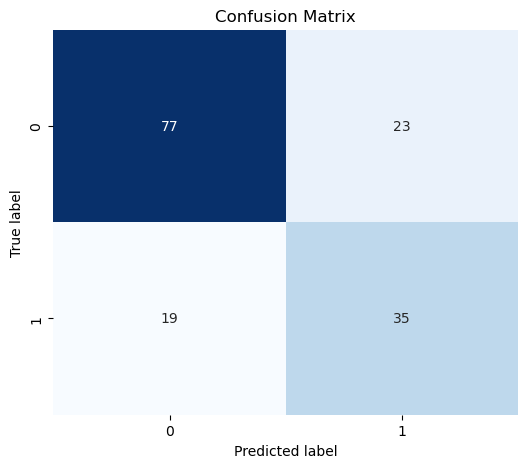

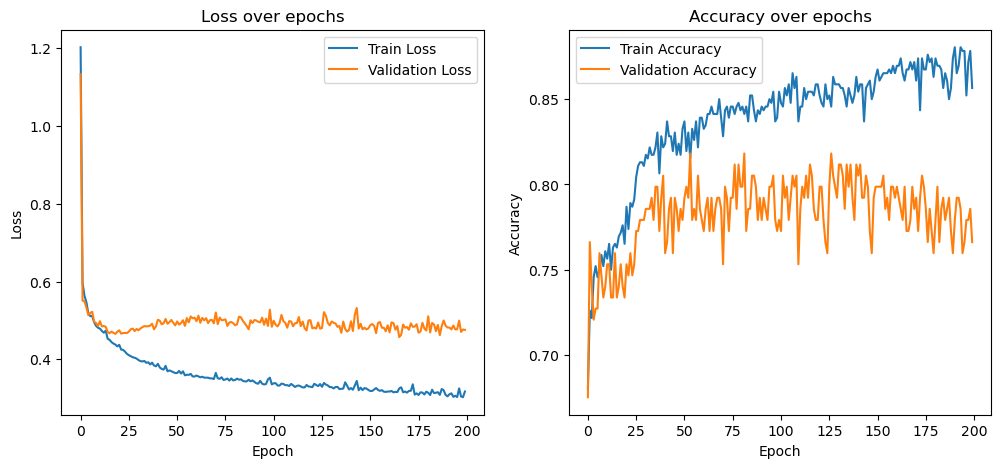

In [95]:
# Matrice de confusion
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.show()

# Courbes de perte et d’accuracy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Courbe de perte
ax1.plot(train_losses, label='Train Loss')
ax1.plot(val_losses, label='Validation Loss')
ax1.set_title('Loss over epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()

# Courbe d’accuracy
ax2.plot(train_accuracies, label='Train Accuracy')
ax2.plot(val_accuracies, label='Validation Accuracy')
ax2.set_title('Accuracy over epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()

plt.show()


In [99]:
nn = NeuralNetwork(layer_sizes, learning_rate=0.5, optimizer="adam")
train_losses , val_losses , train_accuracies , val_accuracies = nn.train(X_train,y_train,X_val,y_val,epochs = 200 , batch_size = 128)

 Epoch 0 , Train Loss : 1.0399, Val Loss : 0.9124 ,  Train Acc : 0.6435 , Val Acc : 0.6558
 Epoch 10 , Train Loss : 0.4710, Val Loss : 0.4502 ,  Train Acc : 0.7848 , Val Acc : 0.7597
 Epoch 20 , Train Loss : 0.4447, Val Loss : 0.4570 ,  Train Acc : 0.7935 , Val Acc : 0.7597
 Epoch 30 , Train Loss : 0.4174, Val Loss : 0.4570 ,  Train Acc : 0.8087 , Val Acc : 0.7727
 Epoch 40 , Train Loss : 0.4292, Val Loss : 0.4655 ,  Train Acc : 0.8152 , Val Acc : 0.7662
 Epoch 50 , Train Loss : 0.4431, Val Loss : 0.4393 ,  Train Acc : 0.8000 , Val Acc : 0.7662
 Epoch 60 , Train Loss : 0.4369, Val Loss : 0.4539 ,  Train Acc : 0.8022 , Val Acc : 0.7403
 Epoch 70 , Train Loss : 0.4277, Val Loss : 0.4483 ,  Train Acc : 0.8065 , Val Acc : 0.7662
 Epoch 80 , Train Loss : 0.4402, Val Loss : 0.4716 ,  Train Acc : 0.7978 , Val Acc : 0.7857
 Epoch 90 , Train Loss : 0.4325, Val Loss : 0.4453 ,  Train Acc : 0.8022 , Val Acc : 0.7468
 Epoch 100 , Train Loss : 0.4637, Val Loss : 0.4781 ,  Train Acc : 0.7761 , Val A

In [101]:
y_pred = nn.predict(X_test)
y_pred = (y_pred >= 0.5).astype(int)
print("\nRapport de classification (Test set) : ")
print(classification_report(y_test,y_pred))


Rapport de classification (Test set) : 
              precision    recall  f1-score   support

           0       0.80      0.79      0.79       100
           1       0.62      0.63      0.62        54

    accuracy                           0.73       154
   macro avg       0.71      0.71      0.71       154
weighted avg       0.73      0.73      0.73       154



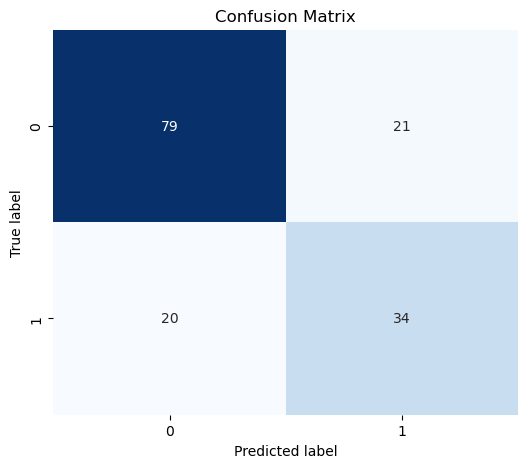

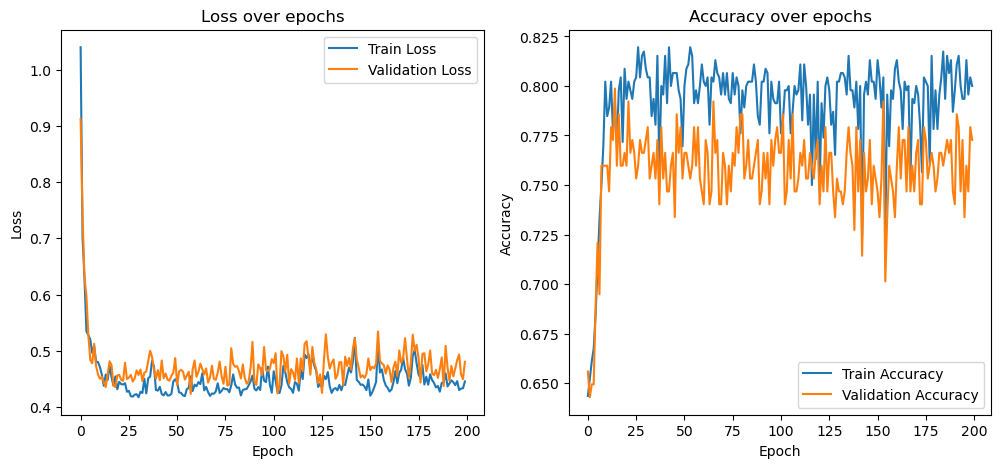

In [103]:
# Matrice de confusion
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.show()

# Courbes de perte et d’accuracy
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Courbe de perte
ax1.plot(train_losses, label='Train Loss')
ax1.plot(val_losses, label='Validation Loss')
ax1.set_title('Loss over epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()

# Courbe d’accuracy
ax2.plot(train_accuracies, label='Train Accuracy')
ax2.plot(val_accuracies, label='Validation Accuracy')
ax2.set_title('Accuracy over epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()

plt.show()
